# 03 - Ridge regression

**Task:** predict how many packets will be waiting in a switch's queue 20 ms from now, using its recent history.

This notebook is a copy of `01_quickstart.ipynb`. Only the model in step 6 is different.

## 1. Setup

Find the project folder and import what we need. Run the cells from top to bottom with Shift+Enter.

In [11]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # so that "from src..." works

import matplotlib.pyplot as plt
import pandas as pd

from src.evaluate import add_result, score

## 2. Load the tables

`train` is for teaching the model and `val` is for checking it. There is also a `test` table, but it stays closed until the very end (see `TASKS.md`).

In [12]:
train = pd.read_parquet(ROOT / "data/tables/train.parquet")
val = pd.read_parquet(ROOT / "data/tables/val.parquet")
print(len(train), "training rows,", len(val), "validation rows")

196306 training rows, 68097 validation rows


## 3. Look at 5 rows

Each row is one moment of one run. `y` is what we want to predict. `lag_1` is the queue now, `lag_2` is the queue one sample (2 ms) ago, and so on. `README.md` explains all columns.

In [13]:
train.head()

,run_id,t_ms,y,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,mean_10,mean_50,max_50,slope_10,delay_now_ms
0,run_01,109.284102,1,3,4,5,5,6,1,2,3,4,5,3.8,2.40,7,0.036364,3.014
1,run_01,122.988592,1,1,1,2,2,3,3,4,5,5,6,3.2,2.48,7,-0.569697,3.321
2,run_01,128.507045,1,1,1,2,3,1,1,1,2,2,3,1.7,2.48,7,-0.115152,1.905
3,run_01,143.175889,0,1,0,0,0,0,1,1,2,3,1,0.9,2.36,7,-0.212121,1.012
4,run_01,156.394111,0,1,2,2,2,3,1,0,0,0,0,1.1,2.42,7,0.248485,3.342


## 4. Plot one run's queue

Each dot is one row of `run_01`. The queue is often empty and sometimes fills up quickly. Small holes are moments next to lost samples, which are not in the table.

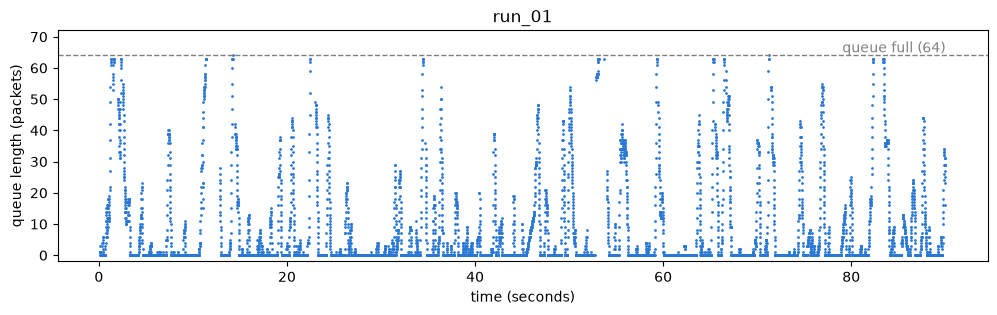

In [14]:
run = train[train["run_id"] == "run_01"]

plt.figure(figsize=(12, 3))
plt.plot(run["t_ms"] / 1000, run["lag_1"], ".", markersize=2, color="#2a78d6")
plt.axhline(64, color="grey", linestyle="--", linewidth=1)
plt.text(90, 65, "queue full (64)", color="grey", ha="right")
plt.ylim(-2, 72)
plt.xlabel("time (seconds)")
plt.ylabel("queue length (packets)")
plt.title("run_01")
plt.show()

## 5. Choose the features

The features are all columns except `run_id` and `t_ms` (they only say where the row comes from) and `y` (the answer).

In [15]:
features = [c for c in train.columns if c not in ["run_id", "t_ms", "y"]]
X_train, y_train = train[features], train["y"]
X_val, y_val = val[features], val["y"]
features

['lag_1',
 'lag_2',
 'lag_3',
 'lag_4',
 'lag_5',
 'lag_6',
 'lag_7',
 'lag_8',
 'lag_9',
 'lag_10',
 'mean_10',
 'mean_50',
 'max_50',
 'slope_10',
 'delay_now_ms']

## 6. Train a ridge regression

Ridge is a linear regression that also keeps its weights small. The setting `alpha` says how strongly. This version uses the default `alpha=1.0`.

In [16]:
from sklearn.linear_model import Ridge

model = Ridge()
model.fit(X_train, y_train)

predictions = {"ridge": model.predict(X_val)}  # name -> predictions for val

## 7. Score it on val

MAE and RMSE are in packets, and lower is better. `add_result` adds one row to `results/results.csv`, the table that compares all models. Every time you run this cell it adds a row again.

In [17]:
for name, y_pred in predictions.items():
    scores = score(y_val, y_pred)
    add_result(name, "val", scores)
    print(f"{name}: MAE {scores['MAE']:.2f} packets, RMSE {scores['RMSE']:.2f} packets")

pd.read_csv(ROOT / "results/results.csv")

ridge: MAE 1.10 packets, RMSE 2.31 packets


,name,split,MAE,RMSE
0,persistence,val,1.2288,2.5126
1,mean_10,val,1.6049,3.1373
2,linear_regression,val,1.0961,2.3100
3,linear_regression,val,1.0961,2.3100
4,linear_regression,val,1.0961,2.3100
5,ridge,val,1.0961,2.3100
6,ridge,val,1.0961,2.3100
7,ridge,val,1.0961,2.3100
8,ridge,val,1.0961,2.3100
9,ridge,val,1.0961,2.3100


## 8. Plot predicted vs actual

Left: every validation row. Dots on the grey line are perfect predictions. Right: 5 seconds of one validation run.

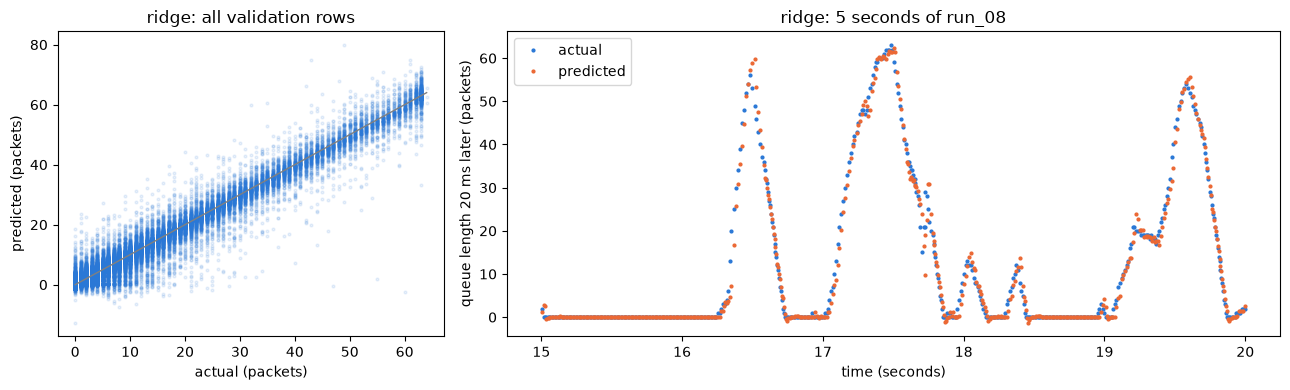

In [18]:
for name, y_pred in predictions.items():
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4), width_ratios=[1, 2])

    left.scatter(y_val, y_pred, s=4, alpha=0.1, color="#2a78d6")
    left.plot([0, 64], [0, 64], color="grey", linewidth=1)  # a perfect prediction
    left.set_xlabel("actual (packets)")
    left.set_ylabel("predicted (packets)")
    left.set_title(f"{name}: all validation rows")

    part = val.assign(y_pred=y_pred)
    part = part[(part["run_id"] == "run_08") & part["t_ms"].between(15_000, 20_000)]
    right.plot(part["t_ms"] / 1000, part["y"], ".", markersize=4, color="#2a78d6", label="actual")
    right.plot(part["t_ms"] / 1000, part["y_pred"], ".", markersize=4, color="#eb6834", label="predicted")
    right.set_xlabel("time (seconds)")
    right.set_ylabel("queue length 20 ms later (packets)")
    right.set_title(f"{name}: 5 seconds of run_08")
    right.legend()

    plt.tight_layout()
    plt.show()

## TODO: tuning

- [ ] `alpha`: try 0.01, 0.1, 1, 10, 100, 1000
- [ ] scale the features first: `make_pipeline(StandardScaler(), Ridge(alpha=...))`
- [ ] fewer features: `mean_10` and `slope_10` are weighted sums of `lag_1` ... `lag_10`, so for a linear model they add nothing new. What changes if you drop them?
- [ ] the queue is never below 0 or above 64, but predictions can be: try `np.clip(y_pred, 0, 64)`
- [ ] new features made from the columns (for example `lag_1 ** 2`, or `lag_1 - lag_10`)

Teach every version on `train` and compare on `val`. Do not open the test table.

In [19]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Plusieurs valeurs de alpha
for a in [0.01, 0.1, 1, 10, 100, 1000]:
    m = Ridge(alpha=a)
    m.fit(X_train, y_train)
    s = score(y_val, m.predict(X_val))
    print(f"ridge alpha={a}: MAE {s['MAE']:.4f}, RMSE {s['RMSE']:.4f}")

# 2. Avec normalisation (StandardScaler)
for a in [1, 10, 100, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a))
    m.fit(X_train, y_train)
    s = score(y_val, m.predict(X_val))
    print(f"scaled ridge alpha={a}: MAE {s['MAE']:.4f}, RMSE {s['RMSE']:.4f}")

# 3. Sans mean_10 et slope_10
feats_reduced = [c for c in features if c not in ["mean_10", "slope_10"]]
m_red = Ridge(alpha=10)
m_red.fit(train[feats_reduced], y_train)
s = score(y_val, m_red.predict(val[feats_reduced]))
print(f"reduced features (alpha=10): MAE {s['MAE']:.4f}, RMSE {s['RMSE']:.4f}")

# 4. Avec clipping entre 0 et 64
m_clip = Ridge(alpha=10)
m_clip.fit(X_train, y_train)
y_pred_clip = np.clip(m_clip.predict(X_val), 0, 64)
s = score(y_val, y_pred_clip)
print(f"ridge alpha=10 + clip(0,64): MAE {s['MAE']:.4f}, RMSE {s['RMSE']:.4f}")

# 5. Nouvelles features (lag_1**2 et lag_1 - lag_10) + scaling + clip
X_tr_new = X_train.assign(lag1_sq=X_train["lag_1"]**2, diff_1_10=X_train["lag_1"] - X_train["lag_10"])
X_va_new = X_val.assign(lag1_sq=X_val["lag_1"]**2, diff_1_10=X_val["lag_1"] - X_val["lag_10"])
m_new = make_pipeline(StandardScaler(), Ridge(alpha=10))
m_new.fit(X_tr_new, y_train)
y_pred_new = np.clip(m_new.predict(X_va_new), 0, 64)
s = score(y_val, y_pred_new)
print(f"new features + scaled + clip: MAE {s['MAE']:.4f}, RMSE {s['RMSE']:.4f}")

ridge alpha=0.01: MAE 1.0961, RMSE 2.3100
ridge alpha=0.1: MAE 1.0961, RMSE 2.3100
ridge alpha=1: MAE 1.0961, RMSE 2.3100
ridge alpha=10: MAE 1.0961, RMSE 2.3100
ridge alpha=100: MAE 1.0961, RMSE 2.3100
ridge alpha=1000: MAE 1.0961, RMSE 2.3096
scaled ridge alpha=1: MAE 1.0961, RMSE 2.3100
scaled ridge alpha=10: MAE 1.0960, RMSE 2.3102
scaled ridge alpha=100: MAE 1.0975, RMSE 2.3141
scaled ridge alpha=1000: MAE 1.1182, RMSE 2.3582
reduced features (alpha=10): MAE 1.0961, RMSE 2.3100
ridge alpha=10 + clip(0,64): MAE 1.0622, RMSE 2.2674
new features + scaled + clip: MAE 1.0582, RMSE 2.2693


In [20]:
# Final model for Role B (Ridge with engineered features, scaling, and [0, 64] clipping)
def add_ridge_features(df):
    return df.assign(
        lag1_sq=df["lag_1"] ** 2,
        diff_1_10=df["lag_1"] - df["lag_10"],
    )

X_train_final = add_ridge_features(X_train)
X_val_final = add_ridge_features(X_val)

final_model = make_pipeline(StandardScaler(), Ridge(alpha=10))
final_model.fit(X_train_final, y_train)

y_pred_final = np.clip(final_model.predict(X_val_final), 0, 64)
final_scores = score(y_val, y_pred_final)

add_result("ridge_final_poly_scaled_clip", "val", final_scores)
print(f"Final Ridge: MAE {final_scores['MAE']:.4f}, RMSE {final_scores['RMSE']:.4f}")

Final Ridge: MAE 1.0582, RMSE 2.2693


## Your notes

## Your notes

- **What I tried:** I tested different regularization strengths (`alpha` from 0.01 to 1000), feature standardization (`StandardScaler`), dropping redundant linear features (`mean_10` and `slope_10`), clipping predictions to the valid physical range `[0, 64]`, and adding non-linear/difference features (`lag_1**2` and `lag_1 - lag_10`).
- **What worked best (settings and val scores):** `make_pipeline(StandardScaler(), Ridge(alpha=10))` with engineered features (`lag_1**2`, `lag_1 - lag_10`) and `np.clip(y_pred, 0, 64)` achieved the best validation MAE of **1.0582** (and RMSE **2.2693**). Compared to the `persistence` baseline (MAE **1.2288**, RMSE **2.5126**), it is better by **0.1706 packets** in MAE (~13.9% error reduction) and **0.2433 packets** in RMSE.
- **What did not help:** Changing `alpha` alone had almost no effect because the dataset is large (~196k rows) relative to the 15 features. Dropping `mean_10` and `slope_10` gave identical results (`1.0961` MAE) since they are linear combinations of `lag_1`...`lag_10`. Combining `StandardScaler` with a very high `alpha=1000` hurt performance (`1.1182` MAE) due to over-shrinkage.
- **Moments where the model is clearly wrong (look at the plots):** Without clipping, the scatter plot shows impossible negative predictions (below 0) when the queue is empty and values above 64 during full-queue bursts. On the 5-second trace of `run_08`, the linear model also slightly overshoots below zero right after sharp drops back to an empty queue, and reacts with a slight lag to sudden traffic spikes.